# Criatura lendária: Esfinge
**Autor: Abraham E. G. Contreras**
### Objetivo: 
Elabore um notebook didático de Jupyter sobre um dos temas listados abaixo, seguindo as 
considerações descritas no item “Expectativas”. A entrega deve ser feita via Pull Request no repositório 
da Biblioteca Real
. A pontuação final será apenas contabilizada mediante ao aceite deste Pull Request, 
que poderá requisitar alterações adicionais após a avaliação. Veja a seção “Os enigmas da Esfinge” 
deste documento para mais informações. Houve uma tentativa de ordenar os temas abaixo do mais 
fácil para o mais difícil. Esta tentativa foi feita apenas como comodidade para o leitor atento, mas é 
importante lembrar que projetar dificuldade em uma escala de apenas uma dimensão é um processo 
que está fadado ao fracasso.
- **Estratégias para lidar com dados desbalanceados em problemas de classificação**
  
### Expectativas: É esperado que o material didático aborde o tema escolhido de forma introdutória, 
mostrando ao leitor questões fundamentais da matemática e estatística que permeiam o tema escolhido 
(caso se aplique). Imagens e gráficos ilustrativos são esperados. O notebook deve ser autocontido, 
ou seja, uma estudante que nunca ouviu falar do tema deve conseguir acompanhar e executar o 
conteúdo do início ao fim. Ser “didático” e ser “autocontido” não significa que o texto deve ser um 
texto longo, é perfeitamente possível passar a mensagem sem a necessidade de “escrever um livro”. É 
necessário também apresentar pelo menos 1 exemplo aplicado em conjunto de dado de sua escolha, 
bem como discussões comparativas com outros tópicos abordados na disciplina (por exemplo, como 
que o Gradient Boosting se difere da Floresta Aleatória?). O trabalho deve ter uma seção chamada 
“Descrição do uso de IA neste trabalho” detalhando como foi a interação com ferramentas de IA para 
a construção dos textos e códigos.

## O que são dados desbalanceados?

Dados desbalanceados ocorrem quando há uma diferença muito grande na quantidade de exemplos entre as classes de um conjunto de dados. Nesse caso, uma classe possui muito mais exemplos do que outra, o que pode dificultar o aprendizado do modelo.

Em problemas de classificação, esse desbalanceamento pode fazer com que o modelo favoreça a **classe majoritária** e tenha dificuldade para identificar a **classe minoritária**. Como resultado, o modelo pode apresentar um bom desempenho para a classe com mais exemplos, mas ter baixa capacidade de identificar corretamente os casos da classe com menos exemplos. Isso pode prejudicar a qualidade das previsões e a capacidade do modelo de funcionar bem com novos dados.

## Quais são os principais cuidados que devemos ter?

### Métricas inadequadas para dados desbalanceados

A **acurácia** pode não ser uma boa métrica para avaliar modelos treinados com dados desbalanceados. Por exemplo, se uma base possui **99% de exemplos negativos** e apenas 1% de exemplos positivos, um modelo que classifica todos os casos como negativos terá 99% de acurácia. Mesmo assim, ele não será capaz de identificar nenhum exemplo da classe positiva.

Isso mostra que uma acurácia alta não significa necessariamente que o modelo tenha um bom desempenho. Em alguns casos, o modelo pode parecer eficiente nas métricas tradicionais, mas falhar justamente na identificação da **classe minoritária**, que pode ser a mais importante para o problema.

Por isso, em conjuntos de dados desbalanceados, é importante não depender apenas da acurácia. Outras métricas, como **precisão, recall e F1-score**, podem fornecer uma visão mais completa do desempenho do modelo e mostrar melhor como ele está identificando cada classe.

### Métricas adequadas para avaliação

Para avaliar modelos com dados desbalanceados, podemos usar métricas que mostram melhor como o modelo está lidando com a **classe minoritária**.

* **Precisão (Precision):** indica, entre os casos que o modelo classificou como positivos, quantos realmente são positivos.

* **Recall:** indica, entre todos os casos que realmente são positivos, quantos o modelo conseguiu identificar corretamente. Essa métrica é importante quando não queremos deixar casos positivos passarem despercebidos.

* **F1-Score:** combina precisão e recall em uma única métrica. Por isso, é útil quando queremos avaliar as duas medidas ao mesmo tempo, principalmente em conjuntos de dados desbalanceados.

* **Matriz de Confusão:** mostra a quantidade de **verdadeiros positivos, verdadeiros negativos, falsos positivos e falsos negativos**. Assim, podemos entender melhor quais tipos de erro o modelo está cometendo.

Matematicamente, todas essas métricas são calculadas a partir de quatro valores da
**matriz de confusão**:

* **VP (Verdadeiro Positivo):** o modelo previu positivo e era positivo.
* **VN (Verdadeiro Negativo):** o modelo previu negativo e era negativo.
* **FP (Falso Positivo):** o modelo previu positivo, mas era negativo.
* **FN (Falso Negativo):** o modelo previu negativo, mas era positivo.

**Precisão (Precision)** mede a proporção de previsões positivas que estavam corretas:

$$
\text{Precisão} = \frac{VP}{VP+FP}
$$

Ou seja, quanto menor o número de **falsos positivos**, maior tende a ser a precisão.


**Recall** mede a proporção dos positivos reais que o modelo conseguiu encontrar:

$$
\text{Recall} = \frac{VP}{VP+FN}
$$

Aqui, o principal objetivo é reduzir os **falsos negativos**. Por isso, o recall é importante quando deixar um caso positivo passar despercebido é um problema.


**F1-Score** é a média harmônica entre precisão e recall:

$$
F1 = 2\frac{\text{Precisão}\times\text{Recall}}
{\text{Precisão}+\text{Recall}}
$$

Ele só será alto quando **precisão e recall forem altos simultaneamente**.


**Matriz de Confusão** organiza os resultados em uma tabela:

$$
\begin{array}{c|cc}
 & \text{Predito +} & \text{Predito -}\\
\hline
\text{Real +} & VP & FN\\
\text{Real -} & FP & VN
\end{array}
$$

A partir desses quatro valores podemos calcular precisão, recall, F1, acurácia e outras métricas.

### Mas o que são modelos preditivos em aprendizado de máquina?

Os modelos preditivos em aprendizado de máquina são ferramentas que identificam relações entre as variáveis de um conjunto de dados para prever um resultado ou uma variável de interesse, chamada de `target`, com base nas informações disponíveis.

Para ilustrar esse problema a partir daqui irei utilizar um ``DataFrame``, que é uma estrutura bidimensional organizada em linhas e colunas de maneira semelhante às planilhas do Excel, para exemplificar os conceitos a serem apresentados.

> *Obs.: Apesar dos ``DataFrames`` serem dados parecidos a planilhas de Excel são ferramentas exclusivas da biblioteca ``Pandas`` em Python*

## Dataset - Dados sobre Feminicídios e Mortalidade Materna na América Latina.

### Dicionário de Dados — América Latina: Feminicídios, Mortalidade Materna e Indicadores de Gênero

> **Fonte:** Kaggle — *Latin America - Femicides & Maternal Mortality*

| # | Nome da Coluna | Nome do Campo | Tipo de Dado | Descrição | Obrigatoriedade / Observação |
|---|---|---|---|---|---|
| 1 | `Unnamed: 0` | Índice / ID | `NUMBER` | Índice numérico sequencial da linha na base de dados. | Campo Interno |
| 2 | `iso3` | Código ISO-3 | `VARCHAR` | Código de 3 letras para identificação padrão do país (ex: `ARG`, `BRA`, `MEX`). | Obrigatório |
| 3 | `country` | Nome do País (Inglês) | `VARCHAR` | Nome do país em inglês (ex: `Argentina`, `Brazil`). | Obrigatório |
| 4 | `year` | Ano de Referência | `NUMBER` | Ano da coleta/registro dos dados estatísticos. | Obrigatório |
| 5 | `le_f` | Expectativa de Vida Feminina | `NUMBER` | Expectativa de vida ao nascer para o sexo feminino (*Life Expectancy - Female*), em anos. | Obrigatório |
| 6 | `country_sp` | Nome do País (Espanhol) | `VARCHAR` | Nome do país traduzido para o espanhol (ex: `Argentina`, `Brasil`). | Obrigatório |
| 7 | `fem_pop` | População Feminina | `NUMBER` | População total do sexo feminino no país para o ano correspondente. | Obrigatório |
| 8 | `mmr` | Razão de Mortalidade Materna | `NUMBER` | Razão de mortalidade materna (*Maternal Mortality Ratio*) por 100.000 nascidos vivos. | Essencial |
| 9 | `gpi` | Índice de Paridade de Gênero | `NUMBER` | Índice de Paridade de Gênero (*Gender Parity Index* - GPI) ou indicador de paz/igualdade de gênero. | Essencial |
| 10 | `femicides_number` | Número de Feminicídios | `NUMBER` | Total de casos de feminicídio (homicídio de mulheres por razões de gênero) registrados no ano. | Essencial |


### Legenda de Classificação dos Campos:
* **Obrigatório:** Campo preenchido na totalidade dos registros do dataset, fundamental para a identificação temporal e geográfica.
* **Essencial:** Campo relevante para análise, podendo conter dados ausentes (valores nulos) para determinados países ou anos.
* **Campo Interno:** Chave de controle ou índice numérico gerado automaticamente na exportação do arquivo.

Antes de começar, vamos exportar as biblotecas que iremos utilizar

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score, classification_report, confusion_matrix, accuracy_score
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score
)

Vamos Ler o ``DataFrame`` a partir da planilha

In [2]:
df = pd.read_csv("LAC_gender_life_death_indices_20230703.csv")#definimos a planilha a ser lida
df = df.convert_dtypes()
df

,Unnamed: 0,iso3,country,year,le_f,country_sp,fem_pop,mmr,gpi,femicides_number
0,0,ARG,Argentina,2008,78.9268,Argentina,20387718,53,1.82,<NA>
1,1,ATG,Antigua and Barbuda,2008,79.088,Antigua y Barbuda,43883,50,<NA>,<NA>
2,2,BHS,Bahamas,2008,75.9615,Bahamas,186970,77,<NA>,<NA>
3,3,BLZ,Belize,2008,74.0447,Belice,152520,59,<NA>,<NA>
4,4,BOL,Bolivia (Plurinational State of),2008,67.8569,Bolivia,4898788,234,1.952,<NA>
...,...,...,...,...,...,...,...,...,...,...
457,457,SUR,Suriname,2021,73.5513,Suriname,307598,120,<NA>,<NA>
458,458,TTO,Trinidad and Tobago,2021,76.4032,Trinidad y Tobago,772874,67,2.024,<NA>
459,459,URY,Uruguay,2021,79.2583,Uruguay,1766768,17,1.782,26
460,460,VCT,Saint Vincent and the Grenadines,2021,72.3958,San Vicente y las Granadinas,51123,68,<NA>,<NA>


## Investigando o ``Dataframe``

> ""Aquele que se conhece é o único senhor de si próprio."" (Ronsard , Pierre)

Antes de tudo, é importante analisar a estrutura do nosso ``DataFrame`` para verificar suas características e entender sua estrutura

Vamos ver qual é o formato do DataFrame? ou seja, quantas linhas e colunas existem nele

In [3]:
df.shape

(462, 10)

Temos 462 linhas e 10 colunas.

Vamos ver quais são os tipos de dados que há no ``DataFrame``?

In [4]:
df.dtypes

Unnamed: 0                   Int64
iso3                string[python]
country             string[python]
year                         Int64
le_f                       Float64
country_sp          string[python]
fem_pop                      Int64
mmr                          Int64
gpi                        Float64
femicides_number             Int64
dtype: object

Temos dados do tipo inteiro (``int64``), float (``Float64``) e string (``string[python]``)

O método **describe()**  é uma forma rápida de calcular algumas ``estatísticas descritivas`` dos dados. Desde que façam sentido é claro

In [5]:
df.describe()

,Unnamed: 0,year,le_f,fem_pop,mmr,gpi,femicides_number
count,462.0,462.0,462.0,462.0,434.0,322.0,182.0
mean,230.5,2014.5,76.441346,9409032.099567,87.721198,2.041925,179.456044
std,133.512172,4.035499,3.719073,20187918.502107,84.079299,0.243252,340.426537
min,0.0,2008.0,46.2514,23904.0,13.0,1.56,0.0
25%,115.25,2011.0,74.99195,198057.5,42.0,1.92825,24.25
50%,230.5,2014.5,76.6819,2956623.0,70.0,2.0195,75.5
75%,345.75,2018.0,78.825125,7696662.25,99.5,2.124,194.0
max,461.0,2021.0,82.7112,109034931.0,506.0,2.757,2048.0


Para ver o problema  de **dados desbalanceados** que queremos identificar, vamos focar em uma coluna em específico, a coluna ``femicides_number`` que diz ao total de casos de feminicídio (homicídio de mulheres por razões de gênero) registrados no ano.

In [6]:
df["femicides_number"].dropna()

9       33
11       1
12     204
21       1
26      16
      ... 
453     22
454    136
455     35
456     80
459     26
Name: femicides_number, Length: 182, dtype: Int64

## Construindo o DataFrame de interesse

Iremos reorganizar o DataFrame para manter apenas as colunas que são relevantes para o que queremos prever. Como já conhecemos os nomes das colunas, podemos usar o método `reindex` para selecioná-las e definir a ordem em que aparecerão.

In [7]:
colunas_interesse = [
    "mmr",
    "le_f",
    "gpi",
    "fem_pop",
    "femicides_number",
]
novo_df = df[colunas_interesse].copy()

# vamos remover os valores ausentes
df_sem_faltantes = novo_df.dropna().copy()
df_sem_faltantes

,mmr,le_f,gpi,fem_pop,femicides_number
9,29,81.0158,1.639,2240104,33
12,92,74.8316,1.987,4700619,204
26,118,74.316,1.842,2801155,16
29,72,74.7729,2.078,704812,19
30,19,80.6754,1.656,1727547,25
...,...,...,...,...,...
453,52,79.594,1.883,2174744,22
454,88,74.7462,2.022,17020361,136
455,84,73.3847,2.005,3338534,35
456,46,75.1492,2.18,3307476,80


Pensamos nessa reestruturação porque queremos prever o número de feminicídios. Assim, o **target**, que representa aquilo que queremos prever, será a coluna `femicides_number`. Já as **features**, que são as informações usadas pelo modelo para fazer a previsão, serão `mmr`, `gpi`, `le_f` e `fem_pop`.

Afinal, por que essas escolhas em específico?

A escolha dessas variáveis foi feita porque elas representam diferentes aspectos relacionados às condições de vida e à situação das mulheres em cada país. Dessa forma, podemos verificar se esses fatores apresentam alguma relação com o número de feminicídios.

 - ``mmr``: Razão de mortalidade materna por 100.000 nascidos vivos.
 - ``le_f``: Expectativa de vida feminina em anos
 - ``gpi``: Índice de Paridade de Gênero ou indicador de paz/igualdade de gênero.

Essas quatro features foram escolhidas porque juntas, elas permitem que o modelo analise diferentes características dos países ao tentar prever `femicides_number`.

Vamos verificar como estão distribuidos esses dados

In [8]:
y = df_sem_faltantes.femicides_number
(y.value_counts()/y.shape[0])*100

femicides_number
26      4.848485
19      3.030303
18      2.424242
25      1.818182
27      1.818182
          ...   
138     0.606061
234     0.606061
1015    0.606061
136     0.606061
80      0.606061
Name: count, Length: 124, dtype: Float64

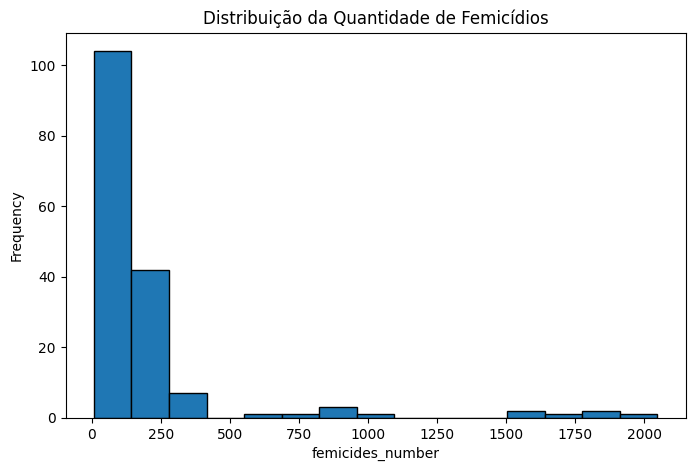

In [9]:
y.plot.hist(bins=15, edgecolor='black', figsize=(8, 5))
plt.xlabel('femicides_number')
plt.title('Distribuição da Quantidade de Femicídios')
plt.show()

Este histograma ilustra a frequência e a assimetria na distribuição do número absoluto de feminicídios (``femicides_number``) entre os países e anos presentes na base de dados.
A grande maioria das observações está concentrada na primeira barra (entre 0 e 250 casos).

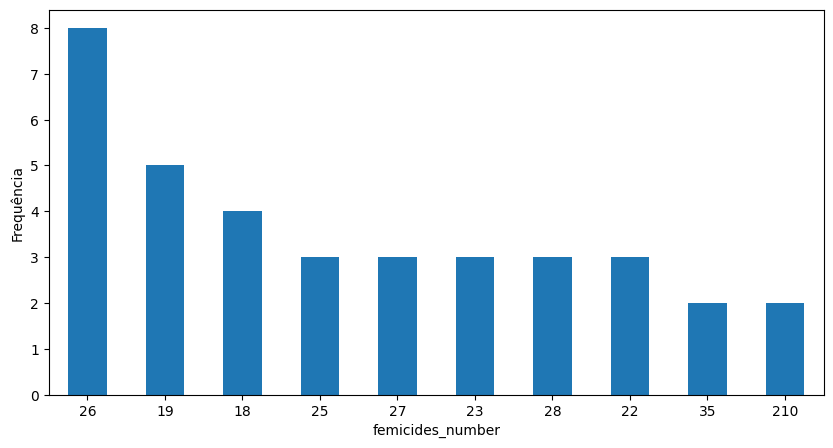

In [10]:
# Mostra apenas os 10 valores mais frequentes
y.value_counts().head(10).plot.bar(figsize=(10, 5))
plt.xticks(rotation=0)
plt.xlabel('femicides_number')
plt.ylabel('Frequência')
plt.show()

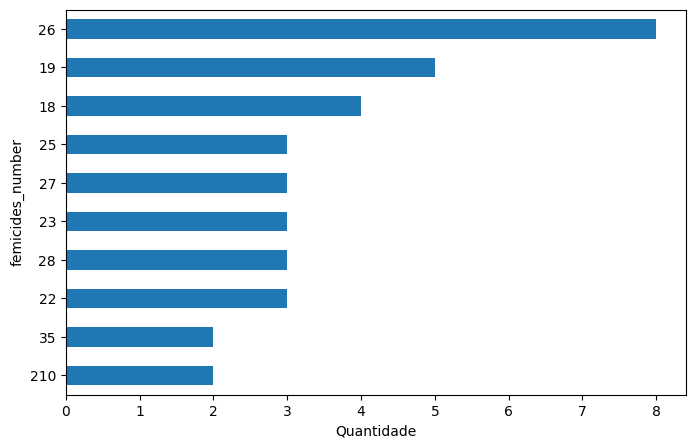

In [11]:
y.value_counts().head(10).plot.barh(figsize=(8, 5)).invert_yaxis()
plt.xlabel('Quantidade')
plt.ylabel('femicides_number')
plt.show()

O gráfico de barras exibe os 10 valores numéricos mais recorrentes para a contagem de feminicídios. O valor 26 é o mais frequente, aparecendo 8 vezes na base, seguido por valores como 19 (5 vezes) e 18 (4 vezes).

Podemos observar que a grande maioria dos países possui um **baixo** número de feminicídios por ano.. Na visão simplificada da coluna, é possível observar com maior frequência o valor `Baixo`. Isso leva a pensar que todos, ou pelo menos a maior parte dos valores, pertence justamente à classe `Baixa`, enquanto a frequência da classe `Alta` é muito menor, ou seja, `Baixa >> Alta`.

Uma possível explicação para o grande número de países classificados com poucos feminicídios pode estar relacionada às diferenças populacionais entre os países, à existência de políticas públicas de prevenção e combate à violência contra a mulher, à eficiência dos sistemas de segurança e registro de ocorrências e também às diferenças na forma como os casos são identificados e contabilizados. Portanto, um número baixo de registros não significa necessariamente que a violência contra a mulher seja inexistente ou menor, pois também pode haver casos não registrados ou diferenças nos critérios de classificação.

Imagine o seguinte cenário: eu tenho vários dados do DataFrame, entretanto desejo prever apenas o número de feminicídios e, para isso, utilizo conceitos de aprendizado de máquina. A maioria dos dados pertence à classe `Baixa`, enquanto uma parcela menor pertence à classe `Alta`. Isso significa que há uma grande possibilidade de ocorrer **viés**, pois números baixos representam a **Classe Majoritária** e números altos representam a **Classe Minoritária**. Essa diferença na quantidade de exemplos entre as classes pode causar um **desbalanceamento dos dados**, fazendo com que alguns modelos tenham maior tendência a prever a classe majoritária e apresentem dificuldade para identificar corretamente os países com valores altos de feminicídios.


## Principais estratégias de balanceamento

* **Undersampling:** estratégia que reduz a quantidade de exemplos da **classe majoritária**, deixando a distribuição entre as classes mais equilibrada. Apesar de ser simples e eficiente em conjuntos de dados muito grandes, pode resultar na perda de informações importantes.

* **Oversampling:** técnica que aumenta a quantidade de exemplos da **classe minoritária**. Isso pode ser feito duplicando exemplos existentes ou criando novos exemplos sintéticos.

* **Uso de Algoritmos Sensíveis ao Desbalanceamento:** alguns algoritmos e modelos possuem métodos que permitem dar **maior importância à classe minoritária** durante o treinamento. Dessa forma, é possível reduzir o efeito do desbalanceamento sem precisar alterar diretamente os dados originais.


## Uso de Algoritmos Sensíveis ao Desbalanceamento

Uma estratégia para lidar com dados desbalanceados é utilizar algoritmos que permitem dar mais importância à **classe minoritária** durante o treinamento. Entre eles estão as **Árvores de Decisão** e a **Floresta Aleatória (Random Forest)**.

Neste caso, usaremos uma **Random Forest**. Podemos utilizar o parâmetro `class_weight` para atribuir um peso maior à classe minoritária. Dessa forma, o modelo dá mais importância aos erros cometidos nessa classe durante o treinamento, o que pode melhorar sua capacidade de identificá-la.

Definimos os atributos(``features``) e o alvo(``target``)

In [12]:
ATRIBUTOS = ["gpi", "le_f", "mmr"]
TARGET_BINARIO = "alto_risco"

Criamos um DataFrame contendo apenas os atributos que serão utilizados no modelo. Em seguida, iremos criar uma nova coluna para **binarizar os dados**, separando os valores em duas categorias: onde **1** representa países com taxa de feminicídio ``acima da mediana regional`` e **0** representa países ``abaixo da mediana``

In [13]:
# Calculando a taxa por 100 mil mulheres
df_sem_faltantes['taxa_feminicidio_100k'] = (df_sem_faltantes['femicides_number']/df_sem_faltantes['fem_pop']) * 100000

# Binarização baseada na taxa (como limite vamos usar a mediana das taxas)
limite_taxa = df_sem_faltantes['taxa_feminicidio_100k'].quantile(0.75)
df_sem_faltantes['alto_risco'] = (df_sem_faltantes['taxa_feminicidio_100k'] >= limite_taxa).astype(int)

In [14]:
print(f"Número de observações válidas: {len(df_sem_faltantes)}")
print(f"Limiar (percentil 75): {limite_taxa:.4f} casos por 100 mil mulheres")

print(
    f"{df_sem_faltantes['alto_risco'].value_counts().rename(index={0: 'Classe 0 — abaixo do limiar', 1: 'Classe 1 — alto risco'}).to_frame('quantidade')}"
)

Número de observações válidas: 165
Limiar (percentil 75): 2.2169 casos por 100 mil mulheres
                             quantidade
alto_risco                             
Classe 0 — abaixo do limiar         123
Classe 1 — alto risco                42


In [15]:
df_novo = df_sem_faltantes.reindex(ATRIBUTOS + [TARGET_BINARIO], axis=1).copy()

Para avaliar a capacidade de generalização do modelo de forma justa, dividimos o conjunto de dados em dois grupos independentes.

Reservamos 30% dos dados para o conjunto de teste e 70% para o treino; Usamos uma semente aleatória para garantir que os resultados sejam exatamente os mesmos a cada execução.

In [16]:
#definindo o split teste e treino
TAMANHO_TESTE = 0.25
SEMENTE_ALEATORIA = 67

Como a distribuição das classes é desbalanceada, o parâmetro ``stratify`` garante que a proporção entre as classes 0 e 1 seja mantida proporcionalmente tanto no treino quanto no teste.

In [17]:
indices = df_novo.index
indices_treino, indices_teste = train_test_split(
    indices, 
    test_size=TAMANHO_TESTE, 
    random_state=SEMENTE_ALEATORIA,
    stratify=df_novo[TARGET_BINARIO]#proporção desbalanceada
)

Definimos o modelo ``Floresta Aleatória`` que utilizaremos mais tarde

In [18]:
modelo_fa = RandomForestClassifier()

Vamos dividir os dados de ``treino`` e dados de ``teste``.

In [19]:
df_treino = df_novo.loc[indices_treino]
df_teste = df_novo.loc[indices_teste]

X_treino = df_treino.reindex(ATRIBUTOS, axis=1).values
y_treino = df_treino[TARGET_BINARIO].values.ravel()

X_teste = df_teste.reindex(ATRIBUTOS, axis=1).values
y_teste = df_teste[TARGET_BINARIO].values.ravel()

print(f"Distribuição de classes no Treino: {np.bincount(y_treino)}")
print(f"Distribuição de classes no Teste: {np.bincount(y_teste)}")

Distribuição de classes no Treino: [92 31]
Distribuição de classes no Teste: [31 11]


A divisão resultou em 123 observações para treinamento e 42 para teste. No conjunto de treinamento, há 92 observações da classe 0 e 31 da classe 1; no conjunto de teste, há 31 observações da classe 0 e 11 da classe 1. Portanto, a classe 0 permanece majoritária em ambos os conjuntos, representando aproximadamente 74,8% do treinamento e 73,8% do teste.

Essa distribuição indica que a divisão preservou proporções semelhantes entre as classes, permitindo avaliar os modelos em dados que mantêm uma estrutura de desbalanceamento próxima àquela utilizada no treinamento.

É importante observar que o conjunto de teste contém apenas 11 observações da classe 1. Assim, cada erro ou acerto nessa classe representa aproximadamente 9,1 pontos percentuais no recall. Consequentemente, pequenas variações no número de casos positivos identificados podem produzir mudanças significativas nas métricas, o que exige cautela na interpretação dos resultados.

### Comparando com baseline

Um modelo mais simples chamado de **modelo de base** ou **baseline**. 

Este é o tipo de modelo que chamamos de *dummy*, *baseline*, linha de base ou modelo fictício. Trata-se de um modelo muito simples que podemos usar para comparar o desempenho de modelos mais complexos. Qualquer modelo com desempenho *pior* que um modelo baseline é um modelo considerado muito ruim.

In [20]:
modelo_baseline = DummyClassifier()
modelo_baseline.fit(X_treino, y_treino)

,strategy,'prior'
,random_state,None
,constant,None


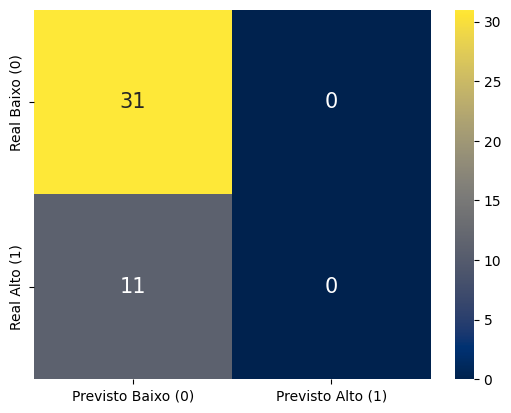

In [21]:
y_verdadeiro = y_teste
y_previsao = modelo_baseline.predict(X_teste)

matriz_conf = confusion_matrix(y_verdadeiro, y_previsao)
df_conf = pd.DataFrame(matriz_conf)

sns.heatmap(df_conf, annot=True, annot_kws={"size": 15}, cmap="cividis", xticklabels=['Previsto Baixo (0)', 'Previsto Alto (1)'],
    yticklabels=['Real Baixo (0)', 'Real Alto (1)'],);

O baseline classifica todas as observações como pertencentes à classe majoritária, isto é, baixo risco. Como o conjunto de teste possui 31 exemplos da classe 0 e 11 da classe 1, o modelo acerta os 31 exemplos negativos e erra os 11 positivos.

Consequentemente, sua acurácia é de 31/42, aproximadamente 73,81%. Apesar desse valor parecer elevado, o recall da classe 1 é zero, pois nenhum exemplo positivo é identificado. A precisão e o F1-score dessa classe também são zero.

Esse resultado demonstra por que a acurácia não deve ser utilizada isoladamente em problemas desbalanceados. Um modelo pode apresentar um percentual elevado de acertos simplesmente por favorecer a classe mais frequente, sem oferecer utilidade na identificação da classe minoritária. Portanto, o baseline estabelece uma referência simples que os modelos mais elaborados devem superar nas métricas relevantes para o problema.

In [22]:
acuracia = accuracy_score(y_verdadeiro, y_previsao)

print(f"Acurácia = {(acuracia*100):.2f}%")

Acurácia = 73.81%


O baseline serve como referência mínima. A acurácia dele pode ser alta, mas como o recall da classe 1 é zero, ele está ignorando a classe minoritária. Um modelo é mais interessante quando melhora as métricas relevantes em relação ao baseline, especialmente recall e F1 da classe 1.

## Algoritmos Sensíveis ao Desbalanceamento: Floresta Aleatória

Instanciamos e treinamos um classificador de Floresta Aleatória.

Parâmetros Principais:
- n_estimators=100: Constrói um conjunto formado por 100 árvores de decisão.

- ``class_weight='balanced'``: Ajusta automaticamente os pesos das classes inversamente proporcionais às suas frequências, compensando o desbalanceamento dos dados.

- n_jobs=4: Paraleliza o processamento utilizando 4 núcleos de CPU para acelerar o treinamento.

Com ``class_weight='balanced'``o modelo passa a considerar a distribuição das classes ao treinar, ajudando a melhorar a previsão da classe minoritária.

O ajuste de Pesos (``Class Weight``), em vez de alterar os dados, modificamos a função de custo do algoritmo. A penalidade para o erro na classe $c$ é ponderada por:
  $$
  w_c = \frac{N}{K \cdot N_c}
  $$
Onde $N$ é o total de amostras, $K$ é o número de classes e $N_c$ é a quantidade de amostras da classe $c$.

In [23]:
modelo_fa = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced', 
    random_state=SEMENTE_ALEATORIA,
    n_jobs=4
)
modelo_fa.fit(X_treino, y_treino)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [24]:
y_previsto = modelo_fa.predict(X_teste)
y_probas = modelo_fa.predict_proba(X_teste)# retorna a probabilidade predita para cada classe, ao inves de apenas mostrar a class label.

print("Relatório de Classificação do Random Forest")
print(classification_report(y_teste, y_previsto))

Relatório de Classificação do Random Forest
              precision    recall  f1-score   support

           0       0.87      0.87      0.87        31
           1       0.64      0.64      0.64        11

    accuracy                           0.81        42
   macro avg       0.75      0.75      0.75        42
weighted avg       0.81      0.81      0.81        42



O modelo ``Random Forest`` apresentou acurácia de aproximadamente 81%, classificando corretamente 34 das 42 observações do conjunto de teste. Entretanto, o desempenho varia entre as classes: para a classe 0, o modelo obteve precisão, recall e F1-score de 0,87; para a classe 1, as três métricas foram de 0,64. Essa diferença indica que o classificador apresenta maior dificuldade para identificar corretamente a classe minoritária.

Considerando especificamente a classe 1, o recall de 0,64 indica que o modelo identificou corretamente cerca de 64% dos casos positivos reais. Como havia 11 observações dessa classe no teste, isso corresponde a aproximadamente 7 casos identificados corretamente e 4 não identificados. A precisão de 0,64 indica que aproximadamente 64% das observações classificadas como positivas realmente pertenciam a essa classe. Portanto, ainda ocorrem tanto falsos negativos quanto falsos positivos.

As médias também ajudam a interpretar o resultado. A média macro de 0,75 atribui o mesmo peso às duas classes, evidenciando a diferença de desempenho entre elas. Já a média ponderada de 0,81 considera a quantidade de observações de cada classe e, por isso, é mais influenciada pelo desempenho na classe majoritária.
o Random Forest apresentou um desempenho geral satisfatório nesta divisão dos dados, mas possui limitações na identificação da classe minoritária.

Visualizamos o impacto e a relevância de cada atributo na tomada de decisão das árvores do modelo.

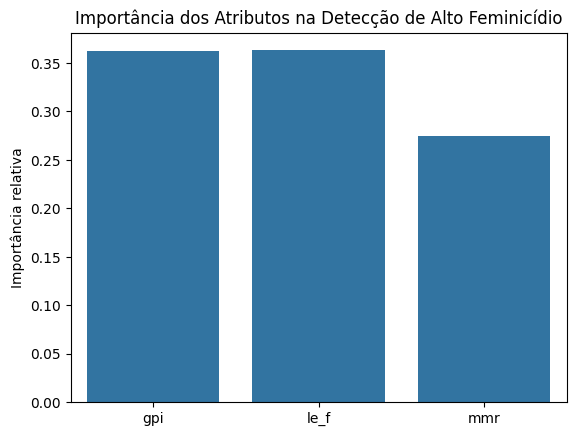

In [25]:
importancia = modelo_fa.feature_importances_

eixo = sns.barplot(x=ATRIBUTOS, y=importancia)
eixo.set_ylabel("Importância relativa")
eixo.set_title("Importância dos Atributos na Detecção de Alto Feminicídio")
plt.show()

O gráfico apresenta a importância relativa atribuída pelo modelo a cada variável utilizada no treinamento. Essa medida indica quanto cada atributo contribuiu para as divisões das árvores, segundo o critério de importância utilizado pela Random Forest.

Uma variável com maior importância foi mais útil para as decisões internas do modelo neste treinamento. Entretanto, essa medida não indica, por si só, a direção da relação entre a variável e o risco previsto, nem demonstra que ela cause alterações na ocorrência de feminicídios.

Além disso, atributos correlacionados podem compartilhar ou redistribuir importância, e os valores podem variar conforme a amostra utilizada. Assim, o resultado deve ser interpretado como uma descrição do funcionamento do modelo.

O ganho relativo de impureza fornecido por cada variável de entrada no modelo de Floresta Aleatória.  Comportamento dos Dados: O índice gpi (Índice de Paridade de Gênero) lidera como a variável de maior peso, seguido pela taxa de mortalidade materna mmr e pela expectativa de vida feminina le_f. 
A visualização mostra que indicadores socioeconômicos de igualdade e saúde estrutural feminina têm poder preditivo equilibrado e relevante para discernir países com taxas de feminicídio acima ou abaixo da mediana regional.

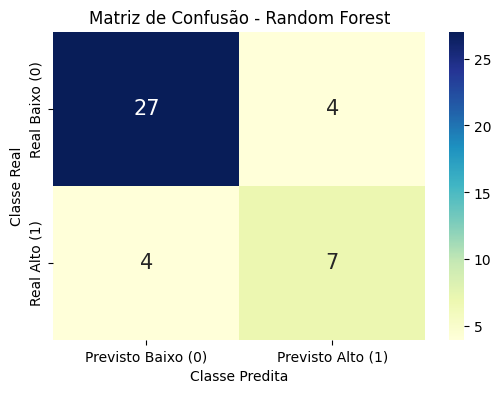

In [26]:
y_verdadeiro = y_teste
y_previsao = modelo_fa.predict(X_teste)

matriz_conf = confusion_matrix(y_verdadeiro, y_previsao)

df_conf = pd.DataFrame(matriz_conf, index=['Baixo Risco (0)', 'Alto Risco (1)'], 
                                   columns=['Previsto Baixo (0)', 'Previsto Alto (1)'])

plt.figure(figsize=(6, 4))
sns.heatmap(df_conf, annot=True, fmt='d', cmap='YlGnBu', annot_kws={"size": 15}, xticklabels=['Previsto Baixo (0)', 'Previsto Alto (1)'],
    yticklabels=['Real Baixo (0)', 'Real Alto (1)'],)
plt.title("Matriz de Confusão - Random Forest")
plt.ylabel("Classe Real")
plt.xlabel("Classe Predita")
plt.show()

Neste problema, os falsos negativos são observações de alto risco classificadas como baixo risco. Os falsos positivos são observações de baixo risco classificadas como alto risco. A distinção é importante porque os dois tipos de erro têm consequências diferentes e afetam as métricas de maneira distinta.

Os resultados do relatório de classificação indicam que o modelo reconheceu aproximadamente sete dos 11 exemplos positivos e deixou de identificar os demais. Isso corresponde a um recall próximo de 0,64 para a classe 1. Como o conjunto de teste é pequeno, cada observação representa uma parcela significativa do resultado.

Analisamos detalhadamente os erros e acertos do modelo por meio de uma matriz de confusão e calculamos o percentual geral de acerto.

In [27]:
acuracia = accuracy_score(y_verdadeiro, y_previsao)

print(f"Acurácia = {(acuracia*100):.2f}%")

Acurácia = 80.95%


In [28]:
print(f"Recall: {recall_score(y_verdadeiro, y_previsao):.2f}")
print(f"Precision: {precision_score(y_verdadeiro, y_previsao):.2f}")

Recall: 0.64
Precision: 0.64


In [29]:
print(classification_report(y_verdadeiro, y_previsao, zero_division=0))

              precision    recall  f1-score   support

           0       0.87      0.87      0.87        31
           1       0.64      0.64      0.64        11

    accuracy                           0.81        42
   macro avg       0.75      0.75      0.75        42
weighted avg       0.81      0.81      0.81        42



A acurácia de 80,95% indica que o modelo classificou corretamente 34 das 42 observações do conjunto de teste. Entretanto, essa métrica não mostra, se o classificador apresenta um bom desempenho na identificação das duas classes. Por isso, também analisamos a precisão, o recall e o F1-score, que permitem compreender melhor os acertos e erros do modelo.

Para a classe 1, o recall de 0,64 indica que o modelo identificou corretamente aproximadamente sete dos 11 exemplos positivos, deixando de reconhecer os outros quatro. A precisão de 0,64 mostra que cerca de 64% das observações classificadas como positivas realmente pertenciam a essa classe. Portanto, embora o modelo consiga identificar parte dos casos positivos, ainda apresenta erros tanto na identificação de exemplos dessa classe quanto na classificação de observações como positivas indevidamente.

Em contraste, a classe 0 apresentou precisão, recall e F1-score de 0,87, indicando um desempenho superior na identificação da classe majoritária. Essa diferença evidencia que o modelo não trata as duas classes com a mesma eficácia. A média macro de 0,75, que atribui o mesmo peso a cada classe, torna essa diferença mais evidente, enquanto a média ponderada de 0,81 é influenciada pela maior quantidade de observações da classe 0.

##  Reamostragem
A reamostragem é uma técnica que pode ser utilizada para equilibrar o conjunto de dados. Existem duas abordagens principais: undersampling e oversampling. No undersampling, você reduz o número de exemplos da classe majoritária. Já no oversampling, você aumenta o número de exemplos da classe minoritária.

**Balanceando o dataset**
Temos 2 classes:
- Classe majoritária: a que possui mais registros
- Classe minoritária: a que possui menos registros

Podemos balancear o dataset reduzindo os registros da classe majoritária (com mais registros) ou aumentando os registros da classe minoritária (com menos registros)

<div style="text-align:center;">
<img src="https://editor.analyticsvidhya.com/uploads/655570_FeIp1t4uEcW5LmSM.png" width="450" weight="450" 
</div>

### Undersampling

O **undersampling** consiste em selecionar apenas uma parte dos dados da **classe majoritária**, de forma que ela tenha aproximadamente a mesma quantidade de exemplos que a classe minoritária. Assim, a distribuição entre as classes fica mais equilibrada. Como são utilizados menos exemplos da classe majoritária, parte dos dados originais é descartada.

### Oversampling

O **oversampling** consiste em aumentar a quantidade de exemplos da **classe minoritária** até que ela tenha uma quantidade semelhante à da classe majoritária. Isso pode ser feito duplicando exemplos existentes ou criando novos exemplos sintéticos. Dessa forma, o conjunto de dados fica mais equilibrado sem precisar remover exemplos da classe majoritária.


Para separar o efeito da reamostragem do efeito do algoritmo, usaremos a **mesma Regressão Logística** nos três cenários:

1. **Sem reamostragem:** treino com a distribuição original.
2. **Undersampling aleatório:** reduz a classe majoritária no conjunto de treino.
3. **Oversampling aleatório:** duplica observações da classe minoritária no conjunto de treino.

A Regressão Logística é sensível à escala das variáveis, então `StandardScaler` será ajustado. O pipeline é ajustado novamente em cada cenário; assim, o escalonador não aprende estatísticas do teste. A reamostragem ocorre apenas nos dados de treino.

Antes de executar cada técnica, pense: o que muda a quantidade de exemplos, a função de aprendizado ou o conjunto de avaliação? Aqui muda apenas a distribuição de treino.

Primeiro, treinamos a Regressão Logística com a distribuição original das classes. Esse resultado será a referência para avaliar se o undersampling ou o oversampling modificam o desempenho do classificador.

O ``StandardScaler`` padroniza os atributos, pois eles podem ter escalas muito diferentes. Ele é ajustado apenas com os dados de treinamento e depois aplicado ao teste. Assim, as informações do conjunto de teste não são usadas para calcular os parâmetros de padronização.

In [30]:
# referência sem reamostragem
modelo_sem = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=SEMENTE_ALEATORIA)
)
modelo_sem.fit(X_treino, y_treino)
pred_sem = modelo_sem.predict(X_teste)

print("Referência sem reamostragem")
print(classification_report(y_teste, pred_sem, zero_division=0))

Referência sem reamostragem
              precision    recall  f1-score   support

           0       0.73      0.87      0.79        31
           1       0.20      0.09      0.12        11

    accuracy                           0.67        42
   macro avg       0.46      0.48      0.46        42
weighted avg       0.59      0.67      0.62        42



A ``Regressão Logística`` treinada com a distribuição original das classes apresentou uma acurácia de aproximadamente 67%, mas esse resultado não representa, por si só, um bom desempenho na identificação da classe minoritária. A principal dificuldade aparece na classe 1, que apresentou precisão de 0,20, recall de 0,09 e F1-score de 0,12.

O recall de 0,09 indica que o modelo identificou corretamente apenas 1 dos 11 exemplos positivos do conjunto de teste, deixando de reconhecer os outros 10. Além disso, a precisão de 0,20 indica que somente 20% das observações classificadas como positivas realmente pertenciam a essa classe. Portanto, o modelo apresenta dificuldade tanto para encontrar os casos positivos quanto para realizar previsões positivas corretas.

Em contrapartida, a classe 0 apresentou recall de 0,87, indicando que aproximadamente 87% das observações dessa classe foram identificadas corretamente. Essa diferença mostra que, na configuração original, a Regressão Logística favorece o reconhecimento da classe majoritária e apresenta baixa capacidade de identificar a classe minoritária.

Observe principalmente as métricas da classe 1. O ``support`` informa quantas observações reais de cada classe existem no conjunto de teste; precisão, recall e F1 mostram diferentes aspectos do desempenho.

Se o ``recall`` da classe 1 for baixo, significa que muitos casos positivos reais não foram identificados. Esse resultado é importante porque um modelo pode acertar vários exemplos da classe majoritária e ainda apresentar dificuldade para reconhecer a classe minoritária. Os próximos experimentos verificam se a reamostragem ajuda a reduzir essa dificuldade.

### Undersampling

#### Reduzindo os registros da classe majoritária
Vamos retirar parte dos dados da classe que possui mais registros.
- É importante ter cuidado para não remover exemplos que contenham informações importantes para o modelo.
- Também precisamos verificar se a quantidade de dados restante é suficiente para realizar o treinamento.
- Uma forma simples de começar é remover registros **aleatoriamente** usando o **[RandomUnderSampler](https://imbalanced-learn.org/stable/references/generated/imblearn.under_sampling.RandomUnderSampler.html)**.

Antes que nada é importante ter instalada a biblioteca: ``imbalanced-learn``

In [31]:
# Instalando a biblioteca
# !pip install -U imbalanced-learn

Função auxiliar

In [32]:
def mostrar_distribuicao(nome, rotulos):
    rotulos = pd.Series(rotulos)

    contagem = rotulos.value_counts().reindex([0, 1], fill_value=0)
    total = len(rotulos)

    print(f"{nome} (n={total}):")
    print(contagem.to_string())
    print("Proporção:")
    print((contagem / total).map(lambda x: f"{x:.1%}").to_string())
    print()

O StandardScaler transforma cada atributo para que tenha média próxima de zero e desvio-padrão próximo de um, calculados a partir do conjunto de treinamento. Isso evita que diferenças de escala entre variáveis, como população e índices, influenciem desproporcionalmente o ajuste da Regressão Logística.

O método ``fit_transform()`` aprende esses parâmetros e transforma os dados de treinamento. Já ``transform()`` aplica os mesmos parâmetros ao conjunto de teste, sem recalculá-los com base nesses dados.

Em seguida, ``fit_resample()`` realiza o oversampling no treinamento padronizado. Assim, o modelo será treinado com a distribuição modificada, mas continuará sendo avaliado no teste original

O ``RandomUnderSampler`` reduz a quantidade de exemplos da classe majoritária por meio de uma seleção aleatória. Neste caso, a classe 0 será reduzida para ficar com uma quantidade semelhante à da classe 1.

A vantagem é equilibrar as classes sem repetir observações minoritárias. A limitação é que exemplos da classe majoritária são descartados e parte da informação disponível pode ser perdida. A reamostragem será aplicada somente ao treino; o teste continuará igual ao usado no cenário de referência.

In [33]:
scaler = StandardScaler()
X_treino_us_scaled = scaler.fit_transform(X_treino)
X_teste_scaled = scaler.transform(X_teste) 

modelo_us = RandomUnderSampler(random_state=SEMENTE_ALEATORIA)
X_treino_us_scaled, y_treino_us = modelo_us.fit_resample(X_treino_us_scaled, y_treino)

Vamos fazer a predição com ``Regressão Logística``

In [34]:
# Avaliando com Regressão Logística
clf_rl_us = LogisticRegression(random_state=SEMENTE_ALEATORIA, max_iter=500)
clf_rl_us.fit(X_treino_us_scaled, y_treino_us)
y_predito_rl_us = clf_rl_us.predict(X_teste_scaled )

A comparação mostra se a quantidade total de observações diminuiu e se as classes ficaram mais equilibradas. Confira tanto as contagens absolutas quanto as proporções: observar apenas as porcentagens pode esconder quantos exemplos foram removidos.

O balanceamento é uma alteração no conjunto usado para aprender, não uma melhoria garantida do modelo. A próxima etapa verifica como o classificador treinado com esses dados se comporta no teste original.

In [35]:
print("Antes do undersampling:")
mostrar_distribuicao("Treino", y_treino)
print("Depois do undersampling:")
mostrar_distribuicao("Treino reamostrado", y_treino_us)

Antes do undersampling:
Treino (n=123):
0    92
1    31
Proporção:
0    74.8%
1    25.2%

Depois do undersampling:
Treino reamostrado (n=62):
0    31
1    31
Proporção:
0    50.0%
1    50.0%



Antes do undersampling, o conjunto de treinamento continha 123 observações: 92 da classe 0 e 31 da classe 1. Após a reamostragem, permaneceram 62 observações, divididas igualmente entre as classes, com 31 exemplos em cada uma.

A técnica removeu 61 observações da classe majoritária, reduzindo o tamanho do conjunto de treinamento pela metade. A proporção de exemplos positivos passou de aproximadamente 25,2% para 50%.

Esse procedimento torna a classe minoritária relativamente mais representada durante o aprendizado, mas não acrescenta novas observações positivas. Sua principal limitação é a perda de informações potencialmente úteis da classe majoritária. Portanto, o balanceamento da distribuição é um resultado direto da técnica, enquanto a melhoria do desempenho preditivo precisa ser verificada separadamente no conjunto de teste original.

In [36]:
print("Undersampling na Regressão Logística")
print(f"Recall: {recall_score(y_teste, y_predito_rl_us):.2f}")
print(f"Precision: {precision_score(y_teste, y_predito_rl_us):.2f}")

Undersampling na Regressão Logística
Recall: 0.73
Precision: 0.40


O undersampling elevou o recall da classe 1 de 0,09 para 0,73 em comparação com a Regressão Logística sem reamostragem. Isso indica uma melhora expressiva na identificação dos casos positivos: considerando as 11 observações positivas do conjunto de teste, o modelo passou de aproximadamente um para oito casos identificados corretamente.

A precisão também aumentou, de 0,20 para 0,40, indicando que uma proporção maior das previsões positivas estava correta. Apesar desse avanço, ainda há falsos positivos e casos positivos não identificados. Nesta comparação, as duas métricas apresentaram resultados superiores após o undersampling.

### Como ler o resultado do undersampling

Compare a linha da classe 1 com a do modelo sem reamostragem. Se o recall aumentar, o modelo encontrou mais positivos reais; se a precisão cair, também passou a produzir mais falsos positivos em relação às previsões positivas. O F1-score ajuda a avaliar esse compromisso, mas a interpretação final depende do contexto.

### Interpretar o resultado do undersampling

Observe principalmente o recall da classe 1 e compare-o com o cenário sem reamostragem. O undersampling **não garante** melhora: remover exemplos pode aumentar a sensibilidade à classe minoritária em alguns conjuntos, mas também pode eliminar informação e piorar a generalização. A conclusão deve vir das métricas calculadas, não de uma expectativa prévia.

<Axes: >

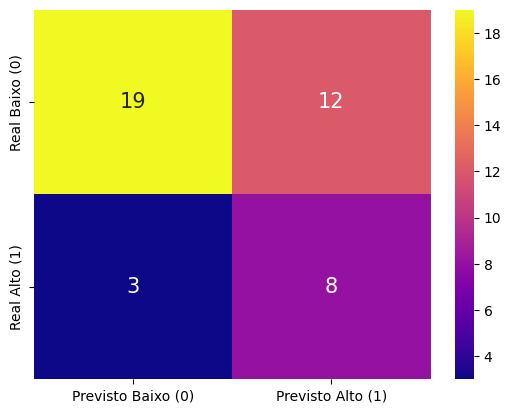

In [37]:
y_verdadeiro = y_teste
matriz_conf = confusion_matrix(y_verdadeiro, y_predito_rl_us)
df_conf = pd.DataFrame(matriz_conf)

sns.heatmap(df_conf,annot=True,annot_kws={"size": 15},cmap="plasma", xticklabels=['Previsto Baixo (0)', 'Previsto Alto (1)'],
    yticklabels=['Real Baixo (0)', 'Real Alto (1)'],)

Após o undersampling, a Regressão Logística apresentou recall de 0,73 e precisão de 0,40 para a classe 1. Comparado ao cenário sem reamostragem, no qual essas métricas eram 0,09 e 0,20, respectivamente, houve uma melhora expressiva na identificação dos exemplos positivos.

O aumento do recall indica que o modelo passou a reconhecer uma proporção maior dos casos reais de alto risco. Entretanto, a precisão de 0,40 mostra que somente quatro em cada dez previsões positivas, aproximadamente, estavam corretas.

Esse resultado evidencia um compromisso entre a identificação de positivos e a ocorrência de falsos positivos. O undersampling parece ter favorecido o reconhecimento da classe minoritária nesta divisão dos dados, mas o custo foi a redução da confiabilidade das previsões positivas. A decisão de utilizar essa estratégia depende, portanto, da importância relativa de cada tipo de erro.

### Oversampling

#### Aumentando os registros da classe minoritária
- Duplicando os valores de maneira aleatória com o **[RandomOverSampler](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.RandomOverSampler.html)**
- A repetição de observações pode aumentar o risco de overfitting, mas não significa que ele necessariamente ocorrerá. Por isso, precisamos avaliar o desempenho em dados que não participaram do treinamento. Neste experimento, o conjunto de teste permanece intacto para essa finalidade.

O StandardScaler transforma cada atributo para que tenha média próxima de zero e desvio-padrão próximo de um, calculados a partir do conjunto de treinamento. Isso evita que diferenças de escala entre variáveis, como população e índices, influenciem desproporcionalmente o ajuste da Regressão Logística.

O método ``fit_transform()`` aprende esses parâmetros e transforma os dados de treinamento. Já ``transform()`` aplica os mesmos parâmetros ao conjunto de teste, sem recalculá-los com base nesses dados.

Em seguida, ``fit_resample()`` realiza o oversampling no treinamento padronizado. Assim, o modelo será treinado com a distribuição modificada, mas continuará sendo avaliado no teste original.

O ``RandomOverSampler`` aumenta a representação da classe minoritária repetindo aleatoriamente exemplos já existentes. Diferentemente do undersampling, ele não precisa remover observações da classe majoritária.

Essa estratégia permite que o modelo veja mais vezes os exemplos da classe minoritária durante o treinamento. Entretanto, as cópias não são novas observações independentes: a repetição pode favorecer o sobreajuste (overfitting). Por isso, o resultado deve ser avaliado em dados de teste que não foram reamostrados.

In [38]:
# Importando o RandomOverSampler do imblearn
scaler = StandardScaler()
X_treino_scaled = scaler.fit_transform(X_treino)
X_teste_scaled = scaler.transform(X_teste)

modelo_os = RandomOverSampler(random_state=SEMENTE_ALEATORIA)
X_treino_os_scaled, y_treino_os = modelo_os.fit_resample(X_treino_scaled, y_treino)

Vamos fazer a predição com ``Regressão Logística``

In [39]:
clf_rl_os = LogisticRegression(random_state=SEMENTE_ALEATORIA, max_iter=500)
clf_rl_os.fit(X_treino_os_scaled, y_treino_os)

y_predito_rl_os = clf_rl_os.predict(X_teste_scaled)

Antes da reamostragem, o treinamento contém 92 exemplos da classe 0 e 31 da classe 1. O objetivo é aumentar a representação da classe 1 até que ambas tenham a mesma quantidade de exemplos.

In [40]:
print("Antes do oversampling:")
mostrar_distribuicao("Treino", y_treino)
print("Depois do oversampling:")
mostrar_distribuicao("Treino reamostrado", y_treino_os)

Antes do oversampling:
Treino (n=123):
0    92
1    31
Proporção:
0    74.8%
1    25.2%

Depois do oversampling:
Treino reamostrado (n=184):
0    92
1    92
Proporção:
0    50.0%
1    50.0%



Antes do oversampling, o treinamento continha 92 observações da classe 0 e 31 da classe 1. Após a aplicação do RandomOverSampler, a classe minoritária passou a conter 92 observações, igualando-se à classe majoritária. O conjunto resultante possui 184 registros.

Diferentemente do undersampling, o oversampling não descarta os exemplos da classe majoritária. Em vez disso, repete observações da classe minoritária, aumentando sua representação durante o treinamento.

É importante observar que o aumento de 123 para 184 registros não corresponde à coleta de 61 novos casos independentes. Os exemplos adicionais são cópias de observações existentes. Assim, o tamanho do conjunto de treinamento aumenta, mas a diversidade de informações originais não cresce na mesma proporção. A eficácia da técnica deve ser avaliada pelo desempenho obtido em dados de teste que não participaram da reamostragem.

In [41]:
print("Oversampling na Regressão Logística")
print(f"Recall: {recall_score(y_teste, y_predito_rl_os):.2f}")
print(f"Precision: {precision_score(y_teste, y_predito_rl_os):.2f}")

Oversampling na Regressão Logística
Recall: 0.91
Precision: 0.43


O oversampling elevou o recall da classe 1 de 0,09 para 0,91 em comparação com a Regressão Logística sem reamostragem. Isso representa uma melhora expressiva na identificação dos casos positivos: considerando as 11 observações positivas do conjunto de teste, o modelo passou de aproximadamente um para dez casos identificados corretamente.

A precisão também aumentou, de 0,20 para 0,43, indicando que uma proporção maior das previsões positivas estava correta. Em comparação com o undersampling, o oversampling também apresentou resultados ligeiramente superiores: o recall passou de 0,73 para 0,91, enquanto a precisão aumentou de 0,40 para 0,43. Portanto, nesta divisão dos dados, o oversampling apresentou o melhor desempenho entre as três configurações da Regressão Logística para identificar a classe minoritária.

### Interpretação do cenário com oversampling

Leia as métricas da classe 1 e compare-as com os cenários anteriores. A repetição de exemplos minoritários pode fazer o modelo prestar mais atenção a essa classe, mas isso não garante melhora em dados novos. Observe simultaneamente recall, precisão e F1-score: aumentar uma métrica pode prejudicar outra.

### Interpretar o resultado do oversampling

Compare precisão, recall e F1 da classe 1 com os dois cenários anteriores. Se o recall aumentar, isso pode significar que o modelo encontra mais casos positivos, mas verifique se a precisão caiu, um possível custo é aumentar os falsos positivos. Oversampling aleatório apenas repete observações; técnicas sintéticas, como SMOTE, são diferentes e exigem cuidados próprios.

<Axes: >

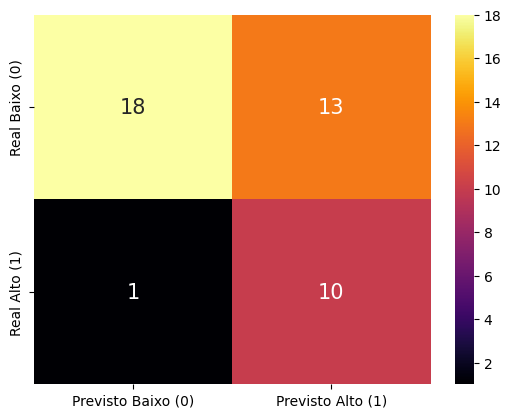

In [42]:
y_verdadeiro = y_teste
matriz_conf = confusion_matrix(y_verdadeiro, y_predito_rl_os)
df_conf = pd.DataFrame(matriz_conf)

sns.heatmap(df_conf,annot=True,annot_kws={"size": 15},cmap="inferno", xticklabels=['Previsto Baixo (0)', 'Previsto Alto (1)'],
    yticklabels=['Real Baixo (0)', 'Real Alto (1)'],)

O modelo treinado com oversampling apresentou recall de 0,91 e precisão de 0,43 para a classe 1. Isso significa que identificou aproximadamente 91% dos exemplos positivos reais, enquanto cerca de 43% das previsões positivas estavam corretas.

Em comparação com o undersampling, o recall aumentou de 0,73 para 0,91, enquanto a precisão passou de 0,40 para aproximadamente 0,43. Portanto, nesta avaliação, o oversampling apresentou uma combinação mais favorável dessas duas métricas para a classe minoritária.

Apesar desse resultado, o modelo ainda produz falsos positivos. A repetição de exemplos pode ajudar a compensar o desbalanceamento, mas não garante que o padrão aprendido se generalize para novos dados. A matriz de confusão deve ser utilizada para verificar a quantidade de erros de cada tipo, complementando a interpretação das métricas agregadas.

**Também existem várias outras formas de fazermos o undersampling e o oversampling e todas elas são explicadas na própria documentação**<br>
- Undersampling:
    - https://imbalanced-learn.org/stable/references/under_sampling.html
- Oversampling:
    - https://imbalanced-learn.org/stable/references/over_sampling.html

##  Comparação dos três cenários

Agora reunimos os resultados dos três cenários avaliados com a mesma Regressão Logística: sem reamostragem, com undersampling e com oversampling. Como todos são avaliados sobre o mesmo conjunto de teste, podemos comparar suas métricas de forma mais consistente.

O gráfico destaca precisão, recall e F1 da classe 1, que é a classe minoritária de interesse. A acurácia também é calculada, mas não deve ser interpretada isoladamente: um modelo pode acertar muitos exemplos da classe majoritária e ainda falhar em identificar os positivos.

,Acurácia,Precisão classe 1,Recall classe 1,F1 classe 1
Estratégia,,,,
Sem reamostragem,0.667,0.200,0.091,0.125
Undersampling,0.643,0.400,0.727,0.516
Oversampling,0.667,0.435,0.909,0.588


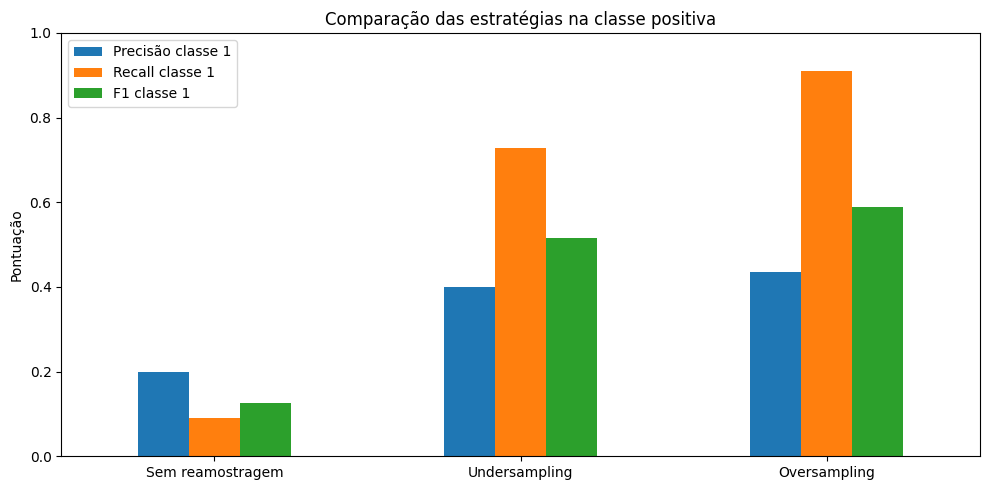

In [43]:
def calcular_metricas(nome, y_real, y_pred):
    return {
        "Estratégia": nome,
        "Acurácia": accuracy_score(y_real, y_pred),
        "Precisão classe 1": precision_score(y_real, y_pred, zero_division=0),
        "Recall classe 1": recall_score(y_real, y_pred, zero_division=0),
        "F1 classe 1": f1_score(y_real, y_pred, zero_division=0)
    }

resultados = pd.DataFrame([
    calcular_metricas("Sem reamostragem", y_teste, pred_sem),
    calcular_metricas("Undersampling", y_teste, y_predito_rl_us),
    calcular_metricas("Oversampling", y_teste, y_predito_rl_os)
]).set_index("Estratégia")

display(resultados.style.format("{:.3f}"))

resultados[["Precisão classe 1", "Recall classe 1", "F1 classe 1"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0
)
plt.title("Comparação das estratégias na classe positiva")
plt.ylabel("Pontuação")
plt.xlabel("")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

A comparação entre as três estratégias mostra diferenças importantes no reconhecimento da classe minoritária. Sem reamostragem, a Regressão Logística apresentou recall de 0,091 e F1-score de 0,125 para a classe 1, indicando dificuldade para identificar os exemplos positivos.

Com undersampling, o recall aumentou para 0,727 e o F1-score para 0,516. O oversampling apresentou os maiores valores entre os três cenários: recall de 0,909, precisão de 0,435 e F1-score de 0,588.

A acurácia, por sua vez, foi de 0,667 sem reamostragem, 0,643 com undersampling e 0,667 com oversampling. Esses resultados mostram que o aumento da capacidade de identificar a classe minoritária não exige necessariamente uma elevação da acurácia global.

No geral, o oversampling representou o melhor equilíbrio entre precisão e recall, considerando o F1-score da classe 1. Entretanto, essa conclusão se restringe à divisão de treino e teste utilizada.

O gráfico permite comparar visualmente três aspectos do desempenho da classe positiva: a precisão, o recall e o F1-score. A principal diferença observada está no recall, que aumenta substancialmente após as duas técnicas de reamostragem.

O oversampling alcança recall próximo de 0,91, indicando maior capacidade de encontrar os positivos reais. Seu F1-score de aproximadamente 0,59 também supera o valor de 0,52 do undersampling e o de 0,13 do modelo sem reamostragem.

A precisão permanece inferior ao recall nos dois cenários reamostrados, indicando que o aumento da detecção de positivos vem acompanhado de previsões positivas incorretas.

A escolha final depende do objetivo do modelo. Se o mais importante for evitar que exemplos positivos passem despercebidos, o recall pode receber maior prioridade. Se os falsos positivos forem particularmente custosos, a precisão também deverá ter peso importante na decisão.

Observe as diferenças entre precisão, recall e F1. O recall indica a capacidade de encontrar os positivos reais; a precisão mostra a confiabilidade das previsões positivas; e o F1 combina as duas medidas.

A célula abaixo calcula qual estratégia teve o maior valor em cada métrica. Isso ajuda a localizar os resultados, mas não substitui a interpretação: a estratégia com maior recall pode não ser a melhor se a precisão cair muito. A escolha depende do objetivo e do custo dos diferentes erros.

In [44]:
for metrica in ["Acurácia", "Precisão classe 1", "Recall classe 1", "F1 classe 1"]:
    melhor = resultados[metrica].idxmax()
    valor = resultados[metrica].max()
    print(f"Maior {metrica.lower()}: {melhor} ({valor:.3f})")

print("Lembre-se: maior valor em uma métrica não significa, sozinho, melhor modelo.")

Maior acurácia: Sem reamostragem (0.667)
Maior precisão classe 1: Oversampling (0.435)
Maior recall classe 1: Oversampling (0.909)
Maior f1 classe 1: Oversampling (0.588)
Lembre-se: maior valor em uma métrica não significa, sozinho, melhor modelo.


## Comparação com o Baseline

O `DummyClassifier(strategy="most_frequent")` sempre prevê a classe mais frequente no conjunto de treino. Ele não aprende relações entre `mmr`, `le_f` e `gpi`.

Por que incluí-lo? Para responder a uma pergunta básica: **os modelos estão aprendendo algo útil ou apenas reproduzem a classe mais comum?**

Se o baseline tiver acurácia alta, mas recall zero para a classe 1, isso ilustra por que a acurácia isolada é insuficiente. Um modelo mais complexo deve ser comparado com essa referência simples, usando as mesmas observações de teste.

Compare as métricas da classe 1 do baseline com as dos três cenários de Regressão Logística. Se o baseline não identificar nenhum positivo, sua precisão e seu recall para essa classe serão zero, mesmo que sua acurácia seja relativamente alta.

In [45]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_treino, y_treino)
pred_baseline = baseline.predict(X_teste)

print("Baseline: classe mais frequente")
print(classification_report(y_teste, pred_baseline, zero_division=0))

resultados_com_baseline = pd.DataFrame([
    calcular_metricas("Baseline", y_teste, pred_baseline),
    calcular_metricas("Sem reamostragem", y_teste, pred_sem),
    calcular_metricas("Undersampling", y_teste, y_predito_rl_us),
    calcular_metricas("Oversampling", y_teste, y_predito_rl_os)
]).set_index("Estratégia")

display(resultados_com_baseline.style.format("{:.3f}"))

Baseline: classe mais frequente
              precision    recall  f1-score   support

           0       0.74      1.00      0.85        31
           1       0.00      0.00      0.00        11

    accuracy                           0.74        42
   macro avg       0.37      0.50      0.42        42
weighted avg       0.54      0.74      0.63        42



,Acurácia,Precisão classe 1,Recall classe 1,F1 classe 1
Estratégia,,,,
Baseline,0.738,0.000,0.000,0.000
Sem reamostragem,0.667,0.200,0.091,0.125
Undersampling,0.643,0.400,0.727,0.516
Oversampling,0.667,0.435,0.909,0.588


O baseline apresentou acurácia de 0,738, superior à dos três modelos de Regressão Logística avaliados. No entanto, seu recall, sua precisão e seu F1-score para a classe 1 foram iguais a zero, pois ele classificou todas as observações como pertencentes à classe majoritária.

O modelo sem reamostragem também apresentou desempenho limitado na classe minoritária, com F1-score de 0,125. Em contrapartida, o undersampling e o oversampling elevaram esse valor para 0,516 e 0,588, respectivamente.

Entre os cenários analisados, o oversampling apresentou o maior recall e o maior F1-score da classe 1, além de precisão superior à do undersampling. Assim, foi a estratégia mais favorável para reconhecer a classe minoritária nesta avaliação.

O baseline serve como referência mínima. Se a acurácia dele for alta, mas o recall da classe 1 for zero, ele está ignorando a classe minoritária. Um modelo é mais interessante quando melhora as métricas relevantes em relação ao baseline, especialmente recall e F1 da classe 1.

A conclusão deve ser escrita com os valores efetivamente obtidos. Não é adequado afirmar que undersampling ou oversampling “funcionou” sem comparar os resultados.

A comparação deve considerar tanto as métricas quanto o modo como cada estratégia modifica os dados. Nenhuma delas garante melhor generalização em todos os problemas.

## Discussão comparativa entre algoritmos

O objetivo era investigar **diferentes estratégias para lidar com o desbalanceamento das classes e avaliar como elas influenciam o desempenho dos modelos**. Para isso, consideramos três abordagens: o uso de algoritmos com ponderação de classes, o *undersampling* e o *oversampling*. Essas estratégias atuam de maneiras distintas: a primeira modifica a importância atribuída aos erros de cada classe durante o treinamento, enquanto as outras alteram a composição do conjunto de treinamento.

Nos experimentos de reamostragem, mantemos a Regressão Logística como classificador para que seja possível observar mais diretamente os efeitos do *undersampling* e do *oversampling*. O conjunto de teste permanece sem reamostragem em todas as condições, preservando uma base comum para a comparação. O `DummyClassifier` é utilizado como referência adicional, permitindo verificar se os modelos conseguem superar uma estratégia trivial de classificação.

### O que está sendo comparado?

| Experimento ou abordagem | O que acontece no treinamento | Relação com o desbalanceamento |
|---|---|---|
| Modelo sem reamostragem | A Regressão Logística aprende com a distribuição original das classes. | Serve como referência para avaliar o efeito das estratégias de tratamento do desbalanceamento. |
| Algoritmo com ponderação de classes | A função de aprendizado atribui pesos diferentes às classes, aumentando a influência da classe minoritária quando se utiliza uma configuração apropriada, como `class_weight='balanced'`. | Busca reduzir a influência desproporcional da classe majoritária sem modificar diretamente a quantidade de observações. |
| Regressão Logística + *undersampling* | Parte das observações da classe majoritária é removida do conjunto de treinamento. | Reduz a diferença numérica entre as classes, mas pode eliminar exemplos úteis para representar a variabilidade da classe majoritária. |
| Regressão Logística + *oversampling* aleatório | Observações da classe minoritária são replicadas no conjunto de treinamento. | Aumenta sua representação numérica sem descartar observações majoritárias, mas pode favorecer sobreajuste pela repetição de exemplos. |
| `DummyClassifier` (*baseline*) | O modelo utiliza uma regra simples de previsão, sem aprender a relação entre os atributos e o alvo. | Fornece uma referência para verificar se os modelos conseguem superar uma estratégia trivial. |

### Por que manter a Regressão Logística fixa nos experimentos de reamostragem?

A Regressão Logística estima a probabilidade de uma observação pertencer à classe positiva a partir de uma combinação dos atributos de entrada. Ao utilizá-la com os mesmos atributos e a mesma divisão entre treinamento e teste, podemos concentrar a análise nas diferenças associadas ao treinamento com a distribuição original, com *undersampling* ou com *oversampling*.

A ponderação de classes é uma abordagem complementar: em vez de remover ou replicar observações, modifica a importância relativa das classes durante o aprendizado. Assim, as três estratégias não devem ser tratadas como equivalentes, pois atuam sobre aspectos diferentes do processo de treinamento.

Nenhuma delas garante, necessariamente, um desempenho superior. O *undersampling* pode descartar informações relevantes; o *oversampling* aleatório pode dar peso excessivo a observações repetidas; e a ponderação de classes pode alterar o equilíbrio entre falsos positivos e falsos negativos. Por isso, os resultados precisam ser avaliados com cuidado.

### Por que a acurácia, sozinha, não basta?

Quando uma classe é mais frequente que a outra, um classificador pode apresentar uma acurácia aparentemente elevada ao acertar principalmente a classe majoritária e falhar na identificação da classe minoritária. Por esse motivo, além da acurácia, analisamos três métricas da classe positiva:

- **Precisão:** entre as observações classificadas como positivas, qual proporção realmente pertence à classe positiva?
- **Recall (sensibilidade):** entre todas as observações realmente positivas, qual proporção foi identificada pelo modelo?
- **F1-score:** combina precisão e recall por meio da média harmônica, permitindo avaliar conjuntamente essas duas dimensões.

Essas métricas evidenciam diferentes tipos de erro. Um aumento do *recall*, por exemplo, indica que o modelo identifica uma proporção maior dos casos positivos, mas pode vir acompanhado de mais falsos positivos e, consequentemente, de uma redução da precisão.

### O que esta comparação permite concluir, e o que não permite?

Manter o conjunto de teste sem reamostragem permite avaliar todas as estratégias sobre a mesma distribuição de observações, tornando os resultados mais comparáveis. As diferenças observadas indicam como cada abordagem se comportou nesta base de dados e nesta divisão específica, mas não demonstram que uma técnica será sempre superior em outros conjuntos de dados.

Além disso, é importante distinguir as estratégias efetivamente avaliadas daquelas apenas discutidas conceitualmente. A ponderação de classes só pode ser comparada quantitativamente com o *undersampling* e o *oversampling* se seus resultados tiverem sido obtidos em um experimento correspondente, utilizando uma divisão de dados e métricas comparáveis. Da mesma forma, o `DummyClassifier` funciona como referência.

## Conclusão

Investigamos como o desbalanceamento das classes afeta a classificação e se as estratégias de reamostragem ajudam a reconhecer a classe minoritária. A comparação mostra como o undersampling e o oversampling alteram a capacidade do classificador de reconhecer a classe minoritária neste conjunto de teste. A estratégia mais adequada depende da análise entre precisão e recall, além do F1-score e da matriz de confusão. Os resultados não garantem que a mesma estratégia será superior em outros conjuntos de dados ou em outra divisão treino/teste. Com os dados utilizados a técnica de Oversampling teve o maior recall e F1-score da classe 1.

## Referências

ANALYTICS VIDHYA. **Top 5 favorite statistical concepts**. Analytics Vidhya, 2020. Disponível em: https://www.analyticsvidhya.com/blog/2020/11/top-5-favorite-statistical-concepts/. Acesso em: 13 set. 2026.

CONCEITOS.TECH. **Como lidar com dados desbalanceados em Machine Learning**. Conceitos Tech, [s.d.]. Disponível em: https://conceitos.tech/tutoriais/inteligencia-artificial/machine-learning/como-lidar-com-dados-desbalanceados-em-machine-learning/. Acesso em: 13 set. 2026.

IBM. **O que é ajuste de hiperparâmetros?** IBM Think, [s.d.]. Disponível em: https://www.ibm.com/br-pt/think/topics/hyperparameter-tuning. Acesso em: 13 set. 2026.

MARIO FILHO. **Precisão, recall e F1-score em Machine Learning**. Mario Filho, [s.d.]. Disponível em: https://mariofilho.com/precisao-recall-e-f1-score-em-machine-learning/. Acesso em: 13 set. 2026.

MARIO FILHO. **XGBoost e dados desbalanceados**. Mario Filho, [s.d.]. Disponível em: https://mariofilho.com/xgboost-dados-desbalanceados/. Acesso em: 13 set. 2026.

PROFISSÃO BIOTEC. **Dados desbalanceados: ensinando seu modelo da maneira certa a aprender**. Profissão Biotec, [s.d.]. Disponível em: https://profissaobiotec.com.br/dados-desbalanceados-ensinando-seu-modelo-maneira-certa-aprender/. Acesso em: 13 set. 2026.

REGUERIN, Nataly. **Latin America femicides and maternal mortality**. Kaggle, [s.d.]. Disponível em: https://www.kaggle.com/datasets/natalyreguerin/latin-america-femicides-and-maternal-mortality. Acesso em: 13 set. 2026.

MATPLOTLIB. **Colormaps in Matplotlib**. Matplotlib, [s.d.]. Disponível em: https://matplotlib.org/stable/users/explain/colors/colormaps.html. Acesso em: 13 set. 2026.


## Sobre a interação com IA

No desenvolvimento deste trabalho, utilizei ferramentas de inteligência artificial generativa como assistente de suporte. A IA auxiliou na formatação das células em Markdown, Revisão Textual: Correção ortográfica, gramatical e refinamento da fluidez textual da introdução e das explicações metodológicas. Esclarecimento Teórico: Suporte na formulação da explicação didática.
A responsabilidade pela realização do trabalho é inteiramente do aluno, a IA foi utilizada para complementação com revisão e adaptação do autor.